# 03 — Placar Comparativo das 3 Configurações, Agente GeoSampa e Auditoria de Erros

Compara programaticamente no conjunto de teste independente (`avaliacao/test_set.jsonl`, 30 casos):
1. **Base (`Qwen 1.7B`) sem contexto**
2. **Base + RAG simples** (`top-3`, limiar `0.30`)
3. **Sistema Completo (`Qwen 1.7B` + LoRA `r=16` + RAG + Agente GeoSampa + Validador)**

,configuracao,total_casos,json_valido,schema_valido,acuracia_risco,acuracia_canal,seguranca_poda,citacao_fonte,recusa_nao_consta,alucinacao_fonte,alucinacao_tel,lgpd_limpo,acuracia_geral_estrita,latencia_media_ms,latencia_p95_ms,tokens_medios,tps_medio
0,1_base_sem_contexto,30,1.0,1.0000,0.5000,0.4000,0.2667,0.0000,1.0,0.0000,0.2333,1.0,0.2667,4373.7,5608.2,143.8,32.88
1,2_rag_simples,30,1.0,0.9667,0.5000,0.8667,0.5333,0.6818,1.0,0.0333,0.0333,1.0,0.3000,5296.6,7032.1,167.2,31.57
2,3_rag_lora_agente,30,1.0,1.0000,0.9333,0.9667,1.0000,1.0000,1.0,0.0000,0.0000,1.0,0.9000,8661.0,11728.4,154.2,17.81


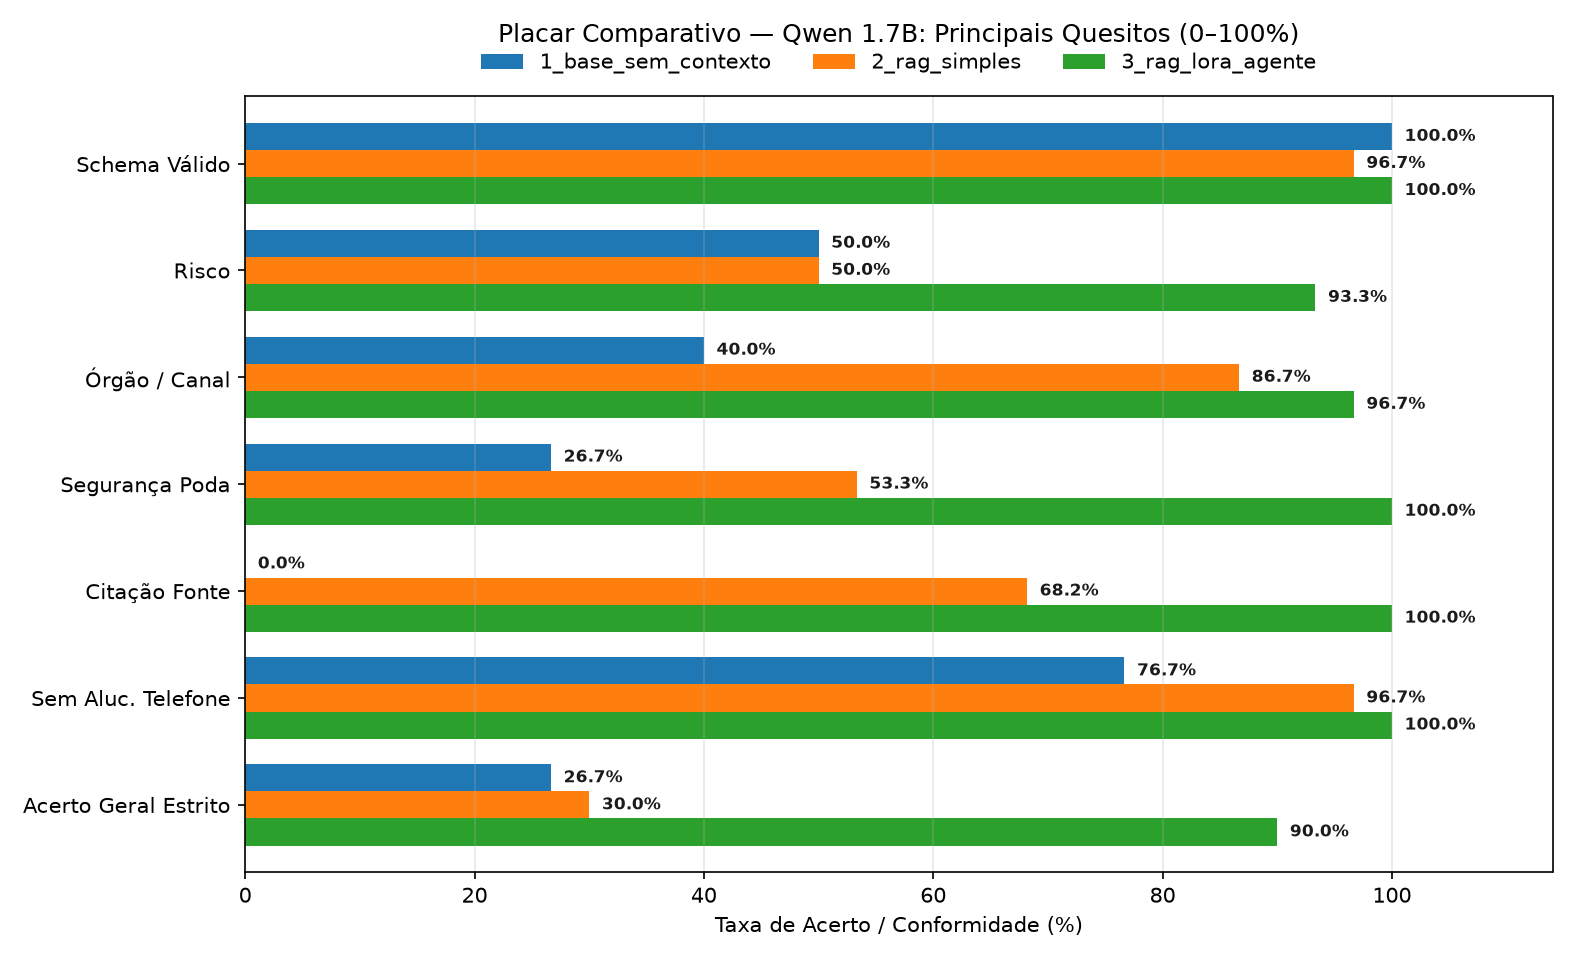

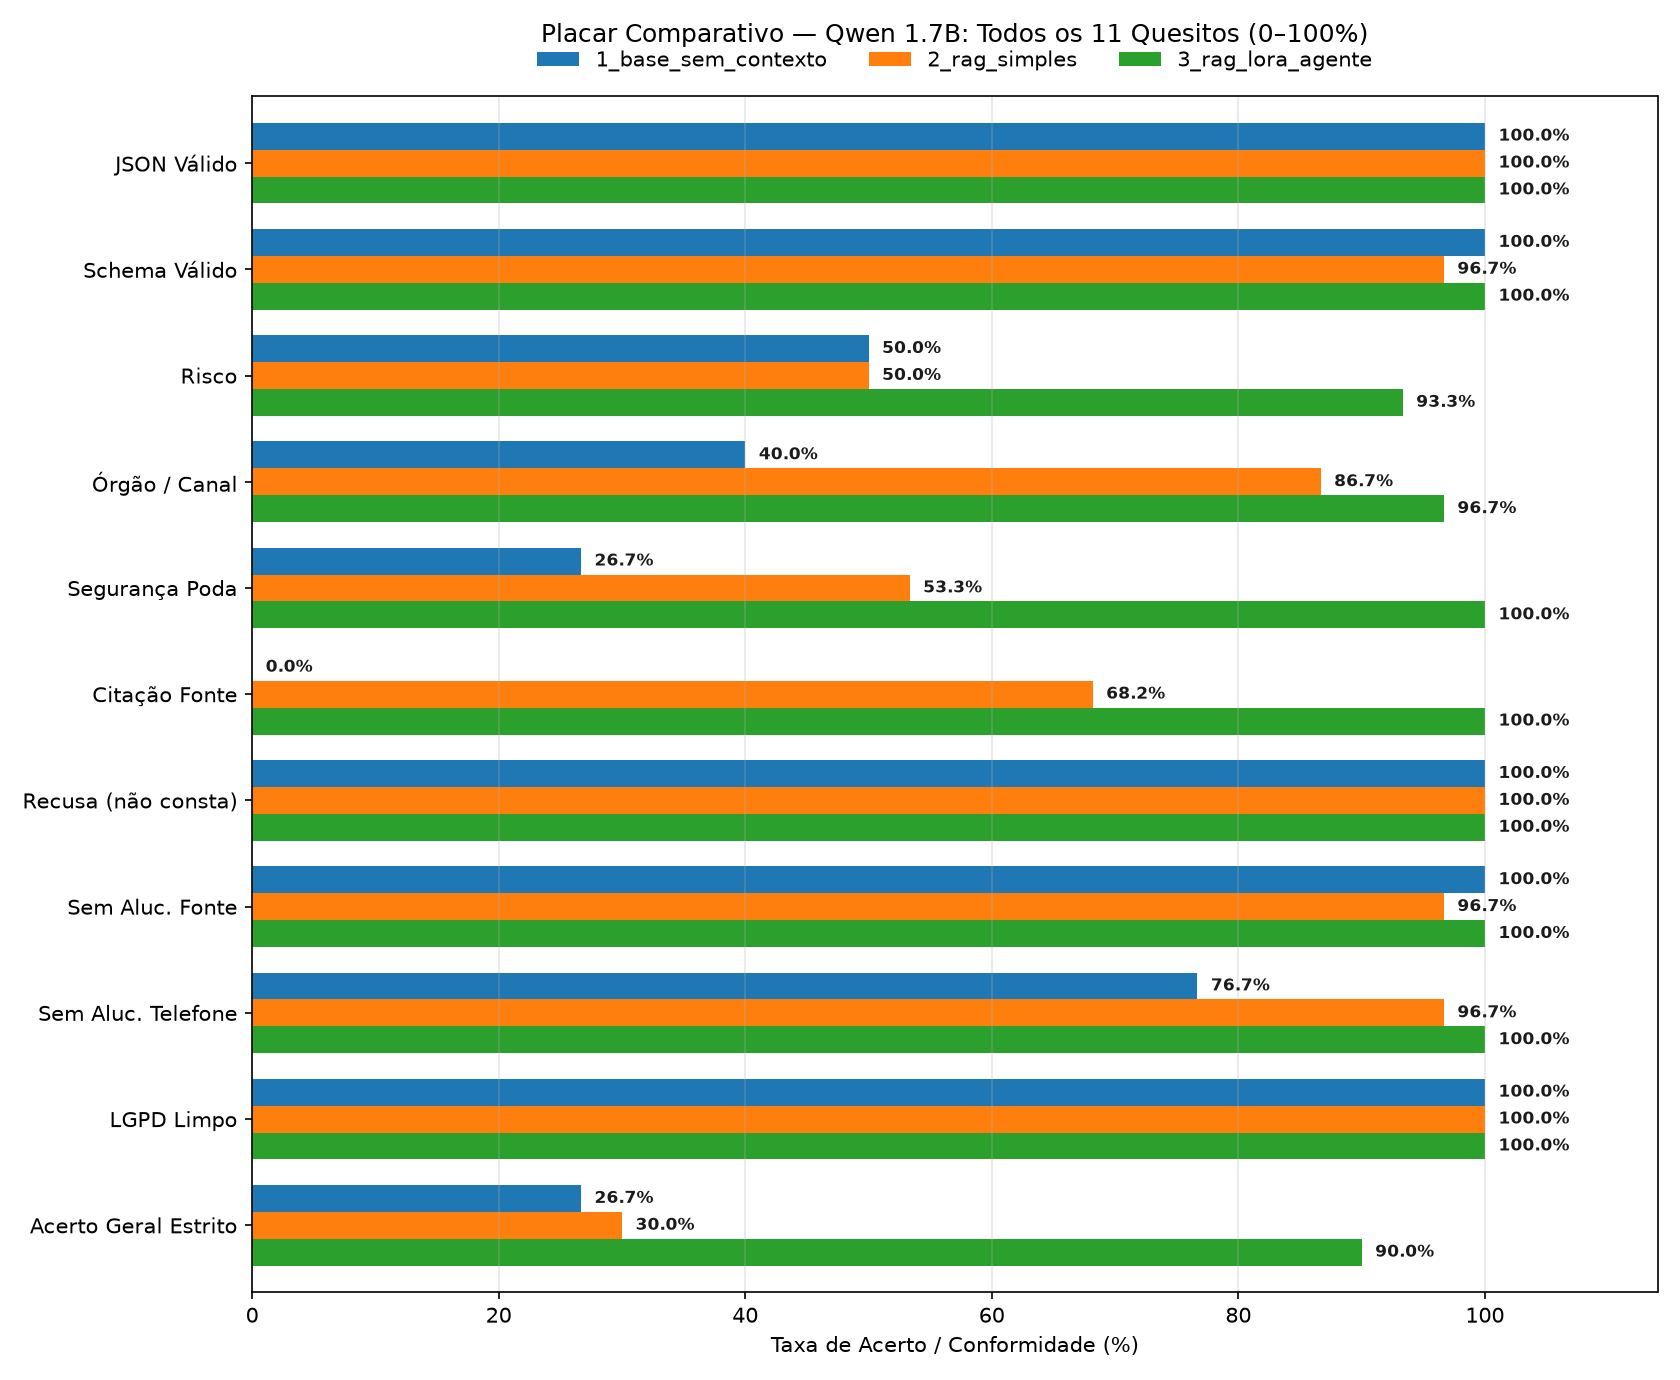

In [1]:
import json
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.common import DIR_ASSETS, DIR_EVAL, load_jsonl

REEXECUTAR_BENCHMARK = False  # True para reavaliar as 3 configurações na GPU
if REEXECUTAR_BENCHMARK or not (DIR_EVAL / 'placar_comparativo.csv').exists():
    from scripts.run_benchmarks import main as run_bench
    run_bench()

df_placar = pd.read_csv(DIR_EVAL / 'placar_comparativo.csv')
display(df_placar)
display(Image(filename=str(DIR_ASSETS / 'placar_comparativo.png')))
display(Image(filename=str(DIR_ASSETS / 'placar_comparativo_completo.png')))

In [2]:
import math
from src.common import DIR_BASE
from src.validator import apply_post_generation_filters, evaluate_prediction

def _wilson_ci95(hits: int, n: int, z: float = 1.96) -> str:
    p = hits / n
    denom = 1 + (z * z) / n
    center = (p + (z * z) / (2 * n)) / denom
    half = (z * math.sqrt((p * (1 - p) + (z * z) / (4 * n)) / n)) / denom
    return f'[{100*(center-half):.1f}%; {100*(center+half):.1f}%]'

details_all = json.loads((DIR_EVAL / 'benchmark_detalhes.json').read_text(encoding='utf-8'))
cases_by_id = {c['id']: c for c in load_jsonl(DIR_EVAL / 'test_set.jsonl')}
kb_by_id = {c['chunk_id']: c for c in load_jsonl(DIR_BASE / 'knowledge_base.jsonl')}

rag_val_hits = 0
rag_val_clean_hits = 0
PARAPHRASED = {'T08', 'T09', 'T12', 'T14', 'T23', 'T25', 'T27', 'T29'}
for row in details_all['2_rag_simples']:
    c = cases_by_id[row['id']]
    chunks = [kb_by_id[cid] for cid in row['retrieved_ids'] if cid in kb_by_id]
    filtered = apply_post_generation_filters(row['raw_output'], c['pergunta'], chunks)
    ev = evaluate_prediction(c, filtered, retrieved_chunks=chunks)
    if ev['overall_exact']:
        rag_val_hits += 1
        if row['id'] not in PARAPHRASED:
            rag_val_clean_hits += 1

audit_rows = []
for key, label in [
    ('1_base_sem_contexto', '1. Base sem contexto'),
    ('2_rag_simples', '2. RAG simples (sem validador)'),
]:
    items = details_all[key]
    hits = sum(1 for r in items if r['overall_exact'])
    clean = sum(1 for r in items if r['overall_exact'] and r['id'] not in PARAPHRASED)
    audit_rows.append({
        'Configuração': label,
        'Total (30)': f'{hits}/30 ({100*hits/30:.1f}%)',
        'IC95% Wilson': _wilson_ci95(hits, 30),
        'Subconjunto limpo (22)': f'{clean}/22 ({100*clean/22:.1f}%)',
    })
audit_rows.append({
    'Configuração': '2b. RAG simples + validador (sem LoRA)',
    'Total (30)': f'{rag_val_hits}/30 ({100*rag_val_hits/30:.1f}%)',
    'IC95% Wilson': _wilson_ci95(rag_val_hits, 30),
    'Subconjunto limpo (22)': f'{rag_val_clean_hits}/22 ({100*rag_val_clean_hits/22:.1f}%)',
})
items3 = details_all['3_rag_lora_agente']
hits3 = sum(1 for r in items3 if r['overall_exact'])
clean3 = sum(1 for r in items3 if r['overall_exact'] and r['id'] not in PARAPHRASED)
audit_rows.append({
    'Configuração': '3. LoRA + RAG + Agente + Validador',
    'Total (30)': f'{hits3}/30 ({100*hits3/30:.1f}%)',
    'IC95% Wilson': _wilson_ci95(hits3, 30),
    'Subconjunto limpo (22)': f'{clean3}/22 ({100*clean3/22:.1f}%)',
})
display(pd.DataFrame(audit_rows))

,Configuração,Total (30),IC95% Wilson,Subconjunto limpo (22)
0,1. Base sem contexto,8/30 (26.7%),[14.2%; 44.4%],4/22 (18.2%)
1,2. RAG simples (sem validador),9/30 (30.0%),[16.7%; 47.9%],5/22 (22.7%)
2,2b. RAG simples + validador (sem LoRA),12/30 (40.0%),[24.6%; 57.7%],8/22 (36.4%)
3,3. LoRA + RAG + Agente + Validador,27/30 (90.0%),[74.4%; 96.5%],20/22 (90.9%)


### Ablação: o que vem do LoRA, do agente e do validador
Gerada por `python scripts/run_benchmarks.py --ablacao`: as respostas com LoRA são geradas de novo, e cada etapa (agente, filtro de citações, piso de risco) é pontuada sobre a mesma saída do modelo.

In [3]:
df_ablacao = pd.read_csv(DIR_EVAL / 'ablacao_placar.csv')
display(df_ablacao[['configuracao', 'acuracia_risco', 'acuracia_canal', 'acuracia_geral_estrita', 'acuracia_estrita_subconjunto_limpo']])

,configuracao,acuracia_risco,acuracia_canal,acuracia_geral_estrita,acuracia_estrita_subconjunto_limpo
0,A_rag_lora,0.8000,0.9667,0.7333,0.6818
1,B_rag_lora_agente,0.8000,0.9667,0.7667,0.7273
2,C_mais_filtro_de_citacoes,0.8000,0.9667,0.7667,0.7273
3,D_mais_piso_de_risco,0.9333,0.9667,0.9000,0.9091


In [4]:
from src.tools import ArborGridInspector

inspector = ArborGridInspector()
for gid in ['629339', '7457', '612162']:
    ctx, rec = inspector.maybe_build_tool_context(f'Consulte a árvore GeoSampa {gid}')
    print(ctx)

Consulta GeoSampa ID 629339 | Distrito: JARDIM PAULISTA | Subprefeitura: PINHEIROS | Coordenadas: (-23.55591, -46.67957) | Última vistoria SISGAU: 2015-09-22Z | Triagem ArborGrid v3: DIVERGENCIA_PARALAXE | max_contact_direct_px=4664 | max_wind_buffer_px=4728.
Consulta GeoSampa ID 7457 | Distrito: BELA VISTA | Subprefeitura: SE | Coordenadas: (-23.56534, -46.65014) | Última vistoria SISGAU: None | Triagem ArborGrid v3: CRITICO_CONFIRMADO | max_contact_direct_px=65680 | max_wind_buffer_px=40048.
Consulta GeoSampa ID 612162 | Distrito: PINHEIROS | Subprefeitura: PINHEIROS | Coordenadas: (-23.56809, -46.68432) | Última vistoria SISGAU: 2013-06-12Z | Triagem ArborGrid v3: SEGURO | max_contact_direct_px=0 | max_wind_buffer_px=0.


In [5]:
questions = {r['id']: r['pergunta'] for r in load_jsonl(DIR_EVAL / 'test_set.jsonl')}
details = json.loads((DIR_EVAL / 'benchmark_detalhes.json').read_text(encoding='utf-8'))['3_rag_lora_agente']
sample_ids = ['T01', 'T07', 'T16', 'T19', 'T25']
rows = []
for item in details:
    if item['id'] in sample_ids:
        p = item['parsed']
        rows.append({
            'id': item['id'],
            'categoria': item['categoria'],
            'pergunta': questions[item['id']],
            'status': p['status'],
            'nivel_risco': p['nivel_risco'],
            'canal': p['telefone_ou_canal'],
            'fontes': ', '.join(p['fontes']),
        })
display(pd.DataFrame(rows))

,id,categoria,pergunta,status,nivel_risco,canal,fontes
0,T01,emergencia_eletrica,Tem uma árvore na calçada encostando nos fios ...,respondido,emergencia_imediata,156,"ENEL-PODA-REDE, SP156-ROTINA"
1,T07,atendimento_municipal,A árvore da calçada em frente ao meu prédio cr...,respondido,preventivo_rotina,156 ou Portal SP156 (sp156.prefeitura.sp.gov.br),"ENEL-PODA-REDE, SP156-ROTINA"
2,T16,sistema_arborgrid,"Sou morador, CPF 123.456.789-00, meu carro pla...",respondido,preventivo_rotina,156 ou SP156 (sp156.prefeitura.sp.gov.br),"SP156-ROTINA, SP156-DENUNCIA-PODA"
3,T19,consulta_arvore_agente,Verifique os dados da árvore GeoSampa 612736 n...,respondido,preventivo_rotina,SP156 (156 ou sp156.prefeitura.sp.gov.br),"SP156-ROTINA, ARBORGRID-TRIAGEM"
4,T25,nao_consta,Qual o valor exato da taxa de boleto em reais ...,nao_consta,fora_de_escopo,não consta,


In [6]:
audit_path = DIR_EVAL / 'auditoria_erros_reais.md'
if not audit_path.exists():
    from scripts.analyze_errors import main as run_audit
    run_audit()
display(Markdown(audit_path.read_text(encoding='utf-8')))

# Auditoria de Erros Reais no Benchmark

## 1_base_sem_contexto — 22 falha(s) em 30 casos

- **T01** (`emergencia_eletrica`): Órgão/telefone incorreto; Violação da regra de poda própria; Não citou a fonte esperada; Telefone não fundamentado no contexto
  - Pergunta: Tem uma árvore na calçada encostando nos fios e soltando faíscas com cheiro de queimado agora. Quem devo chamar?
  - Esperado: `risco=emergencia_imediata`, `canais=['0800 72 72 196', 'enel']`, `fontes=['ENEL-EMERG-01', 'CHANGELOG-2026-ARBOR', 'ENEL-PODA-REDE']`
  - Trechos recuperados: `[]`
  - Obtido: `status=respondido`, `risco=emergencia_imediata`, `tel=181 - 3000-1111`, `fontes=[]`
- **T02** (`emergencia_eletrica`): Nível de risco incorreto; Órgão/telefone incorreto; Violação da regra de poda própria; Não citou a fonte esperada; Telefone não fundamentado no contexto
  - Pergunta: Um galho arrebentou o cabo de energia da rua em Pinheiros e o fio está no chão estalando. Posso usar o 0800 72 72 120?
  - Esperado: `risco=emergencia_imediata`, `canais=['0800 72 72 196', 'enel']`, `fontes=['ENEL-EMERG-01', 'ENEL-RELAC-02', 'SEGURANCA-FIACAO', 'ENEL-PODA-REDE']`
  - Trechos recuperados: `[]`
  - Obtido: `status=respondido`, `risco=urgente_vistoria`, `tel=0800 72 72 120`, `fontes=[]`
- **T03** (`emergencia_vida`): Nível de risco incorreto; Órgão/telefone incorreto; Violação da regra de poda própria; Não citou a fonte esperada
  - Pergunta: Um fio elétrico caiu em cima do meu carro com minha família dentro durante a chuva, mas não há fogo ainda. O que fazemos?
  - Esperado: `risco=emergencia_imediata`, `canais=['193', '0800 72 72 196', 'bombeiros', 'enel']`, `fontes=['SEGURANCA-FIACAO', 'BOMBEIROS-193']`
  - Trechos recuperados: `[]`
  - Obtido: `status=respondido`, `risco=urgente_vistoria`, `tel=não consta`, `fontes=[]`
- **T04** (`emergencia_vida`): Órgão/telefone incorreto; Violação da regra de poda própria; Não citou a fonte esperada; Telefone não fundamentado no contexto
  - Pergunta: Pegou fogo na copa da árvore junto ao transformador do poste e há risco de cair sobre uma casa. Para qual número ligar primeiro?
  - Esperado: `risco=emergencia_imediata`, `canais=['193', 'bombeiros']`, `fontes=['BOMBEIROS-193', 'CHANGELOG-2026-ARBOR']`
  - Trechos recuperados: `[]`
  - Obtido: `status=respondido`, `risco=emergencia_imediata`, `tel=190.1111-2222`, `fontes=[]`
- **T05** (`emergencia_climatica`): Órgão/telefone incorreto; Violação da regra de poda própria; Não citou a fonte esperada; Telefone não fundamentado no contexto
  - Pergunta: Choveu forte agora e uma árvore caiu fechando toda a rua e bloqueando a passagem, sem fios partidos visíveis. Quem acionar?
  - Esperado: `risco=emergencia_imediata`, `canais=['199', 'defesa civil']`, `fontes=['DEFESA-CIVIL-199']`
  - Trechos recuperados: `[]`
  - Obtido: `status=respondido`, `risco=emergencia_imediata`, `tel=181 - 3000-1111`, `fontes=['1']`
- **T06** (`emergencia_climatica`): Nível de risco incorreto; Violação da regra de poda própria; Não citou a fonte esperada; Telefone não fundamentado no contexto
  - Pergunta: Uma árvore caiu em cima da fiação da rua após o temporal; a equipe da Prefeitura pode cortar os galhos imediatamente antes da Enel chegar?
  - Esperado: `risco=emergencia_imediata`, `canais=['0800 72 72 196', '199', 'enel', 'defesa civil']`, `fontes=['DEFESA-CIVIL-199', 'ENEL-EMERG-01', 'ENEL-PODA-REDE']`
  - Trechos recuperados: `[]`
  - Obtido: `status=respondido`, `risco=urgente_vistoria`, `tel=119`, `fontes=[]`
- **T07** (`atendimento_municipal`): Órgão/telefone incorreto; Violação da regra de poda própria; Não citou a fonte esperada
  - Pergunta: A árvore da calçada em frente ao meu prédio cresceu perto dos fios, mas não há faíscas nem curto-circuito. Como pedir poda preventiva em São Paulo?
  - Esperado: `risco=preventivo_rotina`, `canais=['156', 'sp156']`, `fontes=['SP156-ROTINA', 'CHANGELOG-2026-ARBOR', 'ENEL-PODA-REDE', 'SP156-PODA-PRAZO']`
  - Trechos recuperados: `[]`
  - Obtido: `status=respondido`, `risco=preventivo_rotina`, `tel=11 3111-1111`, `fontes=[]`
- **T08** (`legislacao_sp`): Status errado (respondido vs nao_consta); Nível de risco incorreto; Órgão/telefone incorreto; Violação da regra de poda própria; Não citou a fonte esperada
  - Pergunta: A Prefeitura está demorando para atender o protocolo de poda na calçada pública. Posso contratar um jardineiro particular para cortar os galhos da calçada?
  - Esperado: `risco=preventivo_rotina`, `canais=['156', 'sp156', 'subprefeitura']`, `fontes=['LEI-17794-ART05', 'SP156-ROTINA', 'SP156-PODA-PRAZO']`
  - Trechos recuperados: `[]`
  - Obtido: `status=nao_consta`, `risco=fora_de_escopo`, `tel=não consta`, `fontes=[]`
- **T09** (`legislacao_sp`): Status errado (respondido vs nao_consta); Nível de risco incorreto; Órgão/telefone incorreto; Violação da regra de poda própria; Não citou a fonte esperada
  - Pergunta: Tenho uma árvore dentro do quintal do meu imóvel particular em São Paulo e preciso podar. Qual o prazo de comunicação e exigência legal?
  - Esperado: `risco=preventivo_rotina`, `canais=['subprefeitura', '10 dias']`, `fontes=['LEI-17794-ART18', 'SP156-AREA-INTERNA']`
  - Trechos recuperados: `[]`
  - Obtido: `status=nao_consta`, `risco=fora_de_escopo`, `tel=não consta`, `fontes=[]`
- **T10** (`legislacao_sp`): Status errado (respondido vs nao_consta); Nível de risco incorreto; Violação da regra de poda própria; Não citou a fonte esperada; Telefone não fundamentado no contexto
  - Pergunta: Qual decreto municipal regulamenta os fluxos da Lei 17.794/2022 junto às Subprefeituras e à SVMA em São Paulo?
  - Esperado: `risco=preventivo_rotina`, `canais=['subprefeitura', 'sp156', '156', 'svma']`, `fontes=['DEC-61859-PRZ']`
  - Trechos recuperados: `[]`
  - Obtido: `status=nao_consta`, `risco=fora_de_escopo`, `tel=não consta`, `fontes=[]`
- **T11** (`atendimento_concessionaria`): Status errado (respondido vs nao_consta); Nível de risco incorreto; Órgão/telefone incorreto; Violação da regra de poda própria; Não citou a fonte esperada
  - Pergunta: Quero apenas acompanhar um protocolo comercial antigo aberto com a Enel São Paulo, sem situação de emergência na rua. Qual telefone usar?
  - Esperado: `risco=preventivo_rotina`, `canais=['0800 72 72 120', 'enel']`, `fontes=['ENEL-RELAC-02']`
  - Trechos recuperados: `[]`
  - Obtido: `status=nao_consta`, `risco=fora_de_escopo`, `tel=não consta`, `fontes=[]`
- **T12** (`norma_tecnica`): Nível de risco incorreto; Violação da regra de poda própria; Não citou a fonte esperada
  - Pergunta: Segundo o Manual Técnico da SVMA, quando uma copa sempre encosta na fiação, a solução prioritária deve ser poda drástica em V ou adequar a rede?
  - Esperado: `risco=preventivo_rotina`, `canais=['svma', 'sp156', '156', 'enel']`, `fontes=['SVMA-MANUAL-PODA']`
  - Trechos recuperados: `[]`
  - Obtido: `status=respondido`, `risco=urgente_vistoria`, `tel=não consta`, `fontes=['SVMA']`
- **T13** (`seguranca_trabalho`): Status errado (respondido vs nao_consta); Nível de risco incorreto; Órgão/telefone incorreto; Violação da regra de poda própria; Não citou a fonte esperada
  - Pergunta: Posso usar minha própria escada e serrote para afastar um galho próximo da rede energizada se eu usar luvas comuns?
  - Esperado: `risco=urgente_vistoria`, `canais=['0800 72 72 196', '156', 'sp156', 'enel', 'nr-10']`, `fontes=['NBR-16246-2', 'ENEL-EMERG-01', 'ENEL-PODA-REDE']`
  - Trechos recuperados: `[]`
  - Obtido: `status=nao_consta`, `risco=fora_de_escopo`, `tel=não consta`, `fontes=[]`
- **T14** (`norma_tecnica`): Status errado (respondido vs nao_consta); Órgão/telefone incorreto; Violação da regra de poda própria; Não citou a fonte esperada
  - Pergunta: Uma árvore na via está com o tronco inclinado recentemente e podridão na base das raízes, perto de rua movimentada. Quais critérios guiam a análise de risco de queda?
  - Esperado: `risco=urgente_vistoria`, `canais=['156', 'sp156', '199', 'defesa civil', 'subprefeitura']`, `fontes=['NBR-16246-3']`
  - Trechos recuperados: `[]`
  - Obtido: `status=nao_consta`, `risco=urgente_vistoria`, `tel=não consta`, `fontes=[]`
- **T15** (`sistema_arborgrid`): Status errado (respondido vs nao_consta); Nível de risco incorreto; Órgão/telefone incorreto; Violação da regra de poda própria; Não citou a fonte esperada
  - Pergunta: No sistema ArborGrid, qual é a diferença entre triagem CRITICO e PROXIMIDADE, e o resultado dispensa vistoria de campo?
  - Esperado: `risco=preventivo_rotina`, `canais=['sp156', '156', 'subprefeitura']`, `fontes=['ARBORGRID-TRIAGEM']`
  - Trechos recuperados: `[]`
  - Obtido: `status=nao_consta`, `risco=fora_de_escopo`, `tel=não consta`, `fontes=[]`
- **T16** (`sistema_arborgrid`): Status errado (respondido vs nao_consta); Nível de risco incorreto; Órgão/telefone incorreto; Violação da regra de poda própria; Não citou a fonte esperada
  - Pergunta: Sou morador, CPF 123.456.789-00, meu carro placa ABC1D23 está parado perto da árvore na calçada. Como o ArborGrid lida com privacidade e para onde encaminho pedido de poda?
  - Esperado: `risco=preventivo_rotina`, `canais=['156', 'sp156']`, `fontes=['ARBORGRID-LGPD', 'SP156-ROTINA', 'SP156-PODA-PRAZO']`
  - Trechos recuperados: `[]`
  - Obtido: `status=nao_consta`, `risco=fora_de_escopo`, `tel=não consta`, `fontes=[]`
- **T17** (`consulta_arvore_agente`): Status errado (respondido vs nao_consta); Nível de risco incorreto; Órgão/telefone incorreto; Violação da regra de poda própria; Não citou a fonte esperada
  - Pergunta: Consulte a árvore GeoSampa 629339 no ArborGrid: qual a triagem v3 dela e que encaminhamento deve ser dado?
  - Esperado: `risco=urgente_vistoria`, `canais=['156', 'sp156', 'pinheiros']`, `fontes=['ARBORGRID-TRIAGEM', 'SP156-ROTINA', 'SP156-PODA-PRAZO']`
  - Trechos recuperados: `[]`
  - Obtido: `status=nao_consta`, `risco=fora_de_escopo`, `tel=não consta`, `fontes=[]`
- **T18** (`consulta_arvore_agente`): Nível de risco incorreto; Órgão/telefone incorreto; Violação da regra de poda própria; Não citou a fonte esperada
  - Pergunta: Qual a situação da árvore GeoSampa 612162 registrada no ArborGrid e há necessidade de poda emergencial?
  - Esperado: `risco=preventivo_rotina`, `canais=['sp156', '156', 'pinheiros']`, `fontes=['ARBORGRID-TRIAGEM']`
  - Trechos recuperados: `[]`
  - Obtido: `status=respondido`, `risco=emergencia_imediata`, `tel=não consta`, `fontes=[]`
- **T19** (`consulta_arvore_agente`): Status errado (respondido vs nao_consta); Nível de risco incorreto; Órgão/telefone incorreto; Violação da regra de poda própria; Não citou a fonte esperada
  - Pergunta: Verifique os dados da árvore GeoSampa 612736 no ArborGrid (distrito e risco de proximidade na margem de vento).
  - Esperado: `risco=preventivo_rotina`, `canais=['sp156', '156', 'pinheiros']`, `fontes=['ARBORGRID-TRIAGEM', 'SP156-ROTINA', 'SP156-PODA-PRAZO']`
  - Trechos recuperados: `[]`
  - Obtido: `status=nao_consta`, `risco=fora_de_escopo`, `tel=não consta`, `fontes=[]`
- **T20** (`emergencia_vida`): Status errado (respondido vs nao_consta); Órgão/telefone incorreto; Violação da regra de poda própria; Não citou a fonte esperada
  - Pergunta: Estou dentro do carro atingido por um cabo energizado e o veículo começou a pegar fogo agora. Como devo sair com segurança?
  - Esperado: `risco=emergencia_imediata`, `canais=['193', '0800 72 72 196', 'bombeiros']`, `fontes=['SEGURANCA-FIACAO', 'BOMBEIROS-193']`
  - Trechos recuperados: `[]`
  - Obtido: `status=nao_consta`, `risco=emergencia_imediata`, `tel=não consta`, `fontes=[]`
- **T21** (`norma_tecnica`): Status errado (respondido vs nao_consta); Nível de risco incorreto; Órgão/telefone incorreto; Violação da regra de poda própria; Não citou a fonte esperada
  - Pergunta: Qual norma ABNT trata especificamente das boas práticas de corte e preservação do colar na poda em arborização urbana?
  - Esperado: `risco=preventivo_rotina`, `canais=['sp156', '156', 'svma', 'subprefeitura']`, `fontes=['NBR-16246-1', 'SVMA-MANUAL-PODA']`
  - Trechos recuperados: `[]`
  - Obtido: `status=nao_consta`, `risco=fora_de_escopo`, `tel=não consta`, `fontes=[]`
- **T22** (`regra_operacional`): Violação da regra de poda própria; Não citou a fonte esperada; Telefone não fundamentado no contexto
  - Pergunta: Se uma árvore pública está apenas encostando na fiação sem faísca nem estalo, ligo primeiro no 0800 72 72 196 ou abro SP156?
  - Esperado: `risco=preventivo_rotina`, `canais=['156', 'sp156']`, `fontes=['CHANGELOG-2026-ARBOR', 'SP156-ROTINA', 'ENEL-PODA-REDE', 'SP156-PODA-PRAZO']`
  - Trechos recuperados: `[]`
  - Obtido: `status=respondido`, `risco=preventivo_rotina`, `tel=não consta`, `fontes=[]`

## 2_rag_simples — 21 falha(s) em 30 casos

- **T01** (`emergencia_eletrica`): Violação da regra de poda própria
  - Pergunta: Tem uma árvore na calçada encostando nos fios e soltando faíscas com cheiro de queimado agora. Quem devo chamar?
  - Esperado: `risco=emergencia_imediata`, `canais=['0800 72 72 196', 'enel']`, `fontes=['ENEL-EMERG-01', 'CHANGELOG-2026-ARBOR', 'ENEL-PODA-REDE']`
  - Trechos recuperados: `['ENEL-PODA-REDE', 'SP156-DENUNCIA-PODA', 'SP156-ROTINA']`
  - Obtido: `status=respondido`, `risco=emergencia_imediata`, `tel=0800 72 72 196`, `fontes=['ENEL-PODA-REDE', 'SP156-DENUNCIA-PODA', 'SP156-ROTINA']`
- **T02** (`emergencia_eletrica`): Nível de risco incorreto; Telefone não fundamentado no contexto
  - Pergunta: Um galho arrebentou o cabo de energia da rua em Pinheiros e o fio está no chão estalando. Posso usar o 0800 72 72 120?
  - Esperado: `risco=emergencia_imediata`, `canais=['0800 72 72 196', 'enel']`, `fontes=['ENEL-EMERG-01', 'ENEL-RELAC-02', 'SEGURANCA-FIACAO', 'ENEL-PODA-REDE']`
  - Trechos recuperados: `['SEGURANCA-FIACAO', 'SP156-ROTINA', 'ENEL-EMERG-01']`
  - Obtido: `status=respondido`, `risco=urgente_vistoria`, `tel=0800 72 72 196`, `fontes=['SEGURANCA-FIACAO', 'ENEL-EMERG-01']`
- **T03** (`emergencia_vida`): Nível de risco incorreto
  - Pergunta: Um fio elétrico caiu em cima do meu carro com minha família dentro durante a chuva, mas não há fogo ainda. O que fazemos?
  - Esperado: `risco=emergencia_imediata`, `canais=['193', '0800 72 72 196', 'bombeiros', 'enel']`, `fontes=['SEGURANCA-FIACAO', 'BOMBEIROS-193']`
  - Trechos recuperados: `['SEGURANCA-FIACAO', 'ENEL-EMERG-01', 'CHANGELOG-2026-ARBOR']`
  - Obtido: `status=respondido`, `risco=urgente_vistoria`, `tel=0800 72 72 196`, `fontes=['SEGURANCA-FIACAO', 'ENEL-EMERG-01', 'CHANGELOG-2026-ARBOR']`
- **T04** (`emergencia_vida`): Nível de risco incorreto
  - Pergunta: Pegou fogo na copa da árvore junto ao transformador do poste e há risco de cair sobre uma casa. Para qual número ligar primeiro?
  - Esperado: `risco=emergencia_imediata`, `canais=['193', 'bombeiros']`, `fontes=['BOMBEIROS-193', 'CHANGELOG-2026-ARBOR']`
  - Trechos recuperados: `['BOMBEIROS-193', 'CHANGELOG-2026-ARBOR', 'SEGURANCA-FIACAO']`
  - Obtido: `status=respondido`, `risco=urgente_vistoria`, `tel=193`, `fontes=['BOMBEIROS-193', 'CHANGELOG-2026-ARBOR', 'SEGURANCA-FIACAO']`
- **T05** (`emergencia_climatica`): Nível de risco incorreto
  - Pergunta: Choveu forte agora e uma árvore caiu fechando toda a rua e bloqueando a passagem, sem fios partidos visíveis. Quem acionar?
  - Esperado: `risco=emergencia_imediata`, `canais=['199', 'defesa civil']`, `fontes=['DEFESA-CIVIL-199']`
  - Trechos recuperados: `['SEGURANCA-FIACAO', 'ENEL-PODA-REDE', 'DEFESA-CIVIL-199']`
  - Obtido: `status=respondido`, `risco=urgente_vistoria`, `tel=199`, `fontes=['SEGURANCA-FIACAO', 'DEFESA-CIVIL-199']`
- **T06** (`emergencia_climatica`): Nível de risco incorreto; Violação da regra de poda própria
  - Pergunta: Uma árvore caiu em cima da fiação da rua após o temporal; a equipe da Prefeitura pode cortar os galhos imediatamente antes da Enel chegar?
  - Esperado: `risco=emergencia_imediata`, `canais=['0800 72 72 196', '199', 'enel', 'defesa civil']`, `fontes=['DEFESA-CIVIL-199', 'ENEL-EMERG-01', 'ENEL-PODA-REDE']`
  - Trechos recuperados: `['ENEL-PODA-REDE', 'ENEL-EMERG-01', 'SEGURANCA-FIACAO']`
  - Obtido: `status=respondido`, `risco=urgente_vistoria`, `tel=0800 72 72 196`, `fontes=['ENEL-PODA-REDE', 'ENEL-EMERG-01', 'SEGURANCA-FIACAO']`
- **T07** (`atendimento_municipal`): Violação da regra de poda própria
  - Pergunta: A árvore da calçada em frente ao meu prédio cresceu perto dos fios, mas não há faíscas nem curto-circuito. Como pedir poda preventiva em São Paulo?
  - Esperado: `risco=preventivo_rotina`, `canais=['156', 'sp156']`, `fontes=['SP156-ROTINA', 'CHANGELOG-2026-ARBOR', 'ENEL-PODA-REDE', 'SP156-PODA-PRAZO']`
  - Trechos recuperados: `['ENEL-PODA-REDE', 'SP156-PLANTIO', 'SP156-ROTINA']`
  - Obtido: `status=respondido`, `risco=preventivo_rotina`, `tel=156 ou Portal SP156 (sp156.prefeitura.sp.gov.br)`, `fontes=['ENEL-PODA-REDE', 'SP156-ROTINA']`
- **T08** (`legislacao_sp`): Nível de risco incorreto
  - Pergunta: A Prefeitura está demorando para atender o protocolo de poda na calçada pública. Posso contratar um jardineiro particular para cortar os galhos da calçada?
  - Esperado: `risco=preventivo_rotina`, `canais=['156', 'sp156', 'subprefeitura']`, `fontes=['LEI-17794-ART05', 'SP156-ROTINA', 'SP156-PODA-PRAZO']`
  - Trechos recuperados: `['SP156-PODA-PRAZO', 'SP156-PLANTIO', 'ENEL-PODA-REDE']`
  - Obtido: `status=respondido`, `risco=urgente_vistoria`, `tel=(11) 3230-5156`, `fontes=['SP156-PODA-PRAZO']`
- **T09** (`legislacao_sp`): Violação da regra de poda própria; Não citou a fonte esperada
  - Pergunta: Tenho uma árvore dentro do quintal do meu imóvel particular em São Paulo e preciso podar. Qual o prazo de comunicação e exigência legal?
  - Esperado: `risco=preventivo_rotina`, `canais=['subprefeitura', '10 dias']`, `fontes=['LEI-17794-ART18', 'SP156-AREA-INTERNA']`
  - Trechos recuperados: `['SP156-AREA-INTERNA', 'SP156-PLANTIO', 'SP156-PODA-PRAZO']`
  - Obtido: `status=respondido`, `risco=preventivo_rotina`, `tel=(11) 3230-5156`, `fontes=['SP156-PODA-PRAZO']`
- **T11** (`atendimento_concessionaria`): Nível de risco incorreto; Violação da regra de poda própria; Não citou a fonte esperada
  - Pergunta: Quero apenas acompanhar um protocolo comercial antigo aberto com a Enel São Paulo, sem situação de emergência na rua. Qual telefone usar?
  - Esperado: `risco=preventivo_rotina`, `canais=['0800 72 72 120', 'enel']`, `fontes=['ENEL-RELAC-02']`
  - Trechos recuperados: `['ENEL-RELAC-02', 'ENEL-EMERG-01', 'ENEL-PODA-REDE']`
  - Obtido: `status=respondido`, `risco=fora_de_escopo`, `tel=não consta`, `fontes=[]`
- **T12** (`norma_tecnica`): Nível de risco incorreto; Violação da regra de poda própria
  - Pergunta: Segundo o Manual Técnico da SVMA, quando uma copa sempre encosta na fiação, a solução prioritária deve ser poda drástica em V ou adequar a rede?
  - Esperado: `risco=preventivo_rotina`, `canais=['svma', 'sp156', '156', 'enel']`, `fontes=['SVMA-MANUAL-PODA']`
  - Trechos recuperados: `['SVMA-MANUAL-PODA', 'DEC-61859-PRZ', 'CHANGELOG-2026-ARBOR']`
  - Obtido: `status=respondido`, `risco=urgente_vistoria`, `tel=156 / sp156.prefeitura.sp.gov.br`, `fontes=['SVMA-MANUAL-PODA', 'CHANGELOG-2026-ARBOR']`
- **T13** (`seguranca_trabalho`): Status errado (respondido vs nao_consta); Nível de risco incorreto; Violação da regra de poda própria; Não citou a fonte esperada
  - Pergunta: Posso usar minha própria escada e serrote para afastar um galho próximo da rede energizada se eu usar luvas comuns?
  - Esperado: `risco=urgente_vistoria`, `canais=['0800 72 72 196', '156', 'sp156', 'enel', 'nr-10']`, `fontes=['NBR-16246-2', 'ENEL-EMERG-01', 'ENEL-PODA-REDE']`
  - Trechos recuperados: `['SEGURANCA-FIACAO', 'SVMA-MANUAL-PODA', 'NBR-16246-2']`
  - Obtido: `status=nao_consta`, `risco=fora_de_escopo`, `tel=não consta`, `fontes=[]`
- **T14** (`norma_tecnica`): Órgão/telefone incorreto; Violação da regra de poda própria
  - Pergunta: Uma árvore na via está com o tronco inclinado recentemente e podridão na base das raízes, perto de rua movimentada. Quais critérios guiam a análise de risco de queda?
  - Esperado: `risco=urgente_vistoria`, `canais=['156', 'sp156', '199', 'defesa civil', 'subprefeitura']`, `fontes=['NBR-16246-3']`
  - Trechos recuperados: `['NBR-16246-3', 'NBR-16246-1', 'ENEL-PODA-REDE']`
  - Obtido: `status=respondido`, `risco=urgente_vistoria`, `tel=0800 72 72 196`, `fontes=['NBR-16246-3', 'NBR-16246-1', 'ENEL-PODA-REDE']`
- **T15** (`sistema_arborgrid`): Nível de risco incorreto
  - Pergunta: No sistema ArborGrid, qual é a diferença entre triagem CRITICO e PROXIMIDADE, e o resultado dispensa vistoria de campo?
  - Esperado: `risco=preventivo_rotina`, `canais=['sp156', '156', 'subprefeitura']`, `fontes=['ARBORGRID-TRIAGEM']`
  - Trechos recuperados: `['SVMA-MANUAL-PODA', 'ARBORGRID-TRIAGEM', 'SP156-PODA-PRAZO']`
  - Obtido: `status=respondido`, `risco=urgente_vistoria`, `tel=11 3230-5156`, `fontes=['SVMA-MANUAL-PODA', 'ARBORGRID-TRIAGEM']`
- **T16** (`sistema_arborgrid`): Violação da regra de poda própria
  - Pergunta: Sou morador, CPF 123.456.789-00, meu carro placa ABC1D23 está parado perto da árvore na calçada. Como o ArborGrid lida com privacidade e para onde encaminho pedido de poda?
  - Esperado: `risco=preventivo_rotina`, `canais=['156', 'sp156']`, `fontes=['ARBORGRID-LGPD', 'SP156-ROTINA', 'SP156-PODA-PRAZO']`
  - Trechos recuperados: `['SP156-AREA-INTERNA', 'SP156-ROTINA', 'SP156-DENUNCIA-PODA']`
  - Obtido: `status=respondido`, `risco=preventivo_rotina`, `tel=156`, `fontes=['SP156-ROTINA']`
- **T17** (`consulta_arvore_agente`): Esquema inválido (nivel_risco_invalido:nao_consta); Nível de risco incorreto; Violação da regra de poda própria; Não citou a fonte esperada
  - Pergunta: Consulte a árvore GeoSampa 629339 no ArborGrid: qual a triagem v3 dela e que encaminhamento deve ser dado?
  - Esperado: `risco=urgente_vistoria`, `canais=['156', 'sp156', 'pinheiros']`, `fontes=['ARBORGRID-TRIAGEM', 'SP156-ROTINA', 'SP156-PODA-PRAZO']`
  - Trechos recuperados: `['ARBORGRID-TRIAGEM', 'SP156-AREA-INTERNA', 'SP156-PLANTIO']`
  - Obtido: `status=respondido`, `risco=nao_consta`, `tel=não consta`, `fontes=[]`
- **T18** (`consulta_arvore_agente`): Nível de risco incorreto; Violação da regra de poda própria; Não citou a fonte esperada
  - Pergunta: Qual a situação da árvore GeoSampa 612162 registrada no ArborGrid e há necessidade de poda emergencial?
  - Esperado: `risco=preventivo_rotina`, `canais=['sp156', '156', 'pinheiros']`, `fontes=['ARBORGRID-TRIAGEM']`
  - Trechos recuperados: `['SP156-AREA-INTERNA', 'SP156-ROTINA', 'CHANGELOG-2026-ARBOR']`
  - Obtido: `status=respondido`, `risco=urgente_vistoria`, `tel=156 / sp156.prefeitura.sp.gov.br`, `fontes=['SP156-ROTINA', 'CHANGELOG-2026-ARBOR']`
- **T19** (`consulta_arvore_agente`): Órgão/telefone incorreto; Violação da regra de poda própria; Citação de chunk_id inventado ou ausente no contexto
  - Pergunta: Verifique os dados da árvore GeoSampa 612736 no ArborGrid (distrito e risco de proximidade na margem de vento).
  - Esperado: `risco=preventivo_rotina`, `canais=['sp156', '156', 'pinheiros']`, `fontes=['ARBORGRID-TRIAGEM', 'SP156-ROTINA', 'SP156-PODA-PRAZO']`
  - Trechos recuperados: `['SP156-AREA-INTERNA', 'NBR-16246-3', 'ARBORGRID-TRIAGEM']`
  - Obtido: `status=respondido`, `risco=preventivo_rotina`, `tel=não consta`, `fontes=['GeoSampa 612736']`
- **T20** (`emergencia_vida`): Nível de risco incorreto; Violação da regra de poda própria
  - Pergunta: Estou dentro do carro atingido por um cabo energizado e o veículo começou a pegar fogo agora. Como devo sair com segurança?
  - Esperado: `risco=emergencia_imediata`, `canais=['193', '0800 72 72 196', 'bombeiros']`, `fontes=['SEGURANCA-FIACAO', 'BOMBEIROS-193']`
  - Trechos recuperados: `['SEGURANCA-FIACAO', 'ENEL-EMERG-01', 'BOMBEIROS-193']`
  - Obtido: `status=respondido`, `risco=urgente_vistoria`, `tel=0800 72 72 196`, `fontes=['SEGURANCA-FIACAO', 'ENEL-EMERG-01', 'BOMBEIROS-193']`
- **T21** (`norma_tecnica`): Nível de risco incorreto; Órgão/telefone incorreto; Violação da regra de poda própria; Não citou a fonte esperada
  - Pergunta: Qual norma ABNT trata especificamente das boas práticas de corte e preservação do colar na poda em arborização urbana?
  - Esperado: `risco=preventivo_rotina`, `canais=['sp156', '156', 'svma', 'subprefeitura']`, `fontes=['NBR-16246-1', 'SVMA-MANUAL-PODA']`
  - Trechos recuperados: `['NBR-16246-1', 'LEI-17794-ART05', 'ENEL-PODA-REDE']`
  - Obtido: `status=respondido`, `risco=fora_de_escopo`, `tel=não consta`, `fontes=[]`
- **T22** (`regra_operacional`): Nível de risco incorreto; Órgão/telefone incorreto
  - Pergunta: Se uma árvore pública está apenas encostando na fiação sem faísca nem estalo, ligo primeiro no 0800 72 72 196 ou abro SP156?
  - Esperado: `risco=preventivo_rotina`, `canais=['156', 'sp156']`, `fontes=['CHANGELOG-2026-ARBOR', 'SP156-ROTINA', 'ENEL-PODA-REDE', 'SP156-PODA-PRAZO']`
  - Trechos recuperados: `['SP156-ROTINA', 'CHANGELOG-2026-ARBOR', 'SP156-DENUNCIA-PODA']`
  - Obtido: `status=respondido`, `risco=urgente_vistoria`, `tel=0800 72 72 196`, `fontes=['SP156-ROTINA', 'CHANGELOG-2026-ARBOR']`

## 3_rag_lora_agente — 3 falha(s) em 30 casos

- **T09** (`legislacao_sp`): Órgão/telefone incorreto
  - Pergunta: Tenho uma árvore dentro do quintal do meu imóvel particular em São Paulo e preciso podar. Qual o prazo de comunicação e exigência legal?
  - Esperado: `risco=preventivo_rotina`, `canais=['subprefeitura', '10 dias']`, `fontes=['LEI-17794-ART18', 'SP156-AREA-INTERNA']`
  - Trechos recuperados: `['SP156-AREA-INTERNA', 'SP156-PLANTIO', 'SP156-PODA-PRAZO']`
  - Obtido: `status=respondido`, `risco=preventivo_rotina`, `tel=Central 156 (156) ou SP156 (portal/WhatsApp 11.3230.5156)`, `fontes=['SP156-AREA-INTERNA', 'SP156-PODA-PRAZO']`
- **T17** (`consulta_arvore_agente`): Nível de risco incorreto
  - Pergunta: Consulte a árvore GeoSampa 629339 no ArborGrid: qual a triagem v3 dela e que encaminhamento deve ser dado?
  - Esperado: `risco=urgente_vistoria`, `canais=['156', 'sp156', 'pinheiros']`, `fontes=['ARBORGRID-TRIAGEM', 'SP156-ROTINA', 'SP156-PODA-PRAZO']`
  - Trechos recuperados: `['ARBORGRID-TRIAGEM', 'SP156-AREA-INTERNA', 'SP156-PLANTIO', 'SP156-ROTINA']`
  - Obtido: `status=respondido`, `risco=preventivo_rotina`, `tel=SP156 (156 ou portal sp156.prefeitura.sp.gov.br)`, `fontes=['ARBORGRID-TRIAGEM', 'SP156-AREA-INTERNA']`
- **T22** (`regra_operacional`): Nível de risco incorreto
  - Pergunta: Se uma árvore pública está apenas encostando na fiação sem faísca nem estalo, ligo primeiro no 0800 72 72 196 ou abro SP156?
  - Esperado: `risco=preventivo_rotina`, `canais=['156', 'sp156']`, `fontes=['CHANGELOG-2026-ARBOR', 'SP156-ROTINA', 'ENEL-PODA-REDE', 'SP156-PODA-PRAZO']`
  - Trechos recuperados: `['SP156-ROTINA', 'CHANGELOG-2026-ARBOR', 'SP156-DENUNCIA-PODA']`
  - Obtido: `status=respondido`, `risco=urgente_vistoria`, `tel=SP156 156 ou 0800 72 72 196`, `fontes=['SP156-ROTINA', 'CHANGELOG-2026-ARBOR']`
